# 00 · Aprende desde cero: las ideas que usa este proyecto

**¿Para quién es este cuaderno?** Para cualquier persona, aunque nunca haya estudiado estadística.

Aquí se construyen, **una por una y en orden**, todas las ideas que se usan en los cuadernos 01, 02 y 03. Cada idea se apoya en la anterior, como una escalera:

| Nivel | Qué vas a aprender | Pregunta que responde | Secciones del reporte PDF donde se usa |
|---|---|---|---|
| 🟢 **1 · Lo básico** | Datos, población, muestra, promedio, porcentaje, dispersión | ¿Cómo describo un grupo de clientes? | «Las ideas clave», 1, 3 y 4 |
| 🟡 **2 · El azar** | Por qué se elige al azar, por qué cada muestra da un número distinto, la "campana" | ¿Qué tanto puedo confiar en una muestra? | 2.4 y 5 |
| 🟠 **3 · Intervalos de confianza** | Margen de error, "95 % de confianza", tamaño de muestra | ¿Cómo digo "entre tanto y tanto" con seguridad? | 2.3, 5, 6.1, 6.2 y 6.3 |
| 🔴 **4 · Herramientas de experto** | Comparar grupos, pruebas, remuestreo, tomar decisiones | ¿Cómo uso todo esto para decidir? | 2.4 (χ²), 5.2 (bootstrap), 5.3, 5.4, 6.1, 7 |

**Cómo leer cada idea.** Todas siguen el mismo formato, de lo más simple a lo más técnico:

> 🧠 **En palabras simples:** la idea sin tecnicismos.
> 🍲 **Ejemplo cotidiano:** la misma idea en una situación de todos los días.
> 💻 **Lo vemos con los datos:** un pequeño cálculo con los clientes del banco.
> 🎓 **Nivel experto:** el nombre técnico y la fórmula, por si quieres profundizar.

Puedes quedarte sólo con las dos primeras partes de cada idea y aun así entender todo el proyecto.

> 📄 **En el reporte PDF:** este cuaderno es el Anexo B (guía de conceptos). La tabla «Seis ideas para entender todo el proyecto» (Tabla 0) y el glosario del Anexo C resumen lo que aquí se explica con calma.



In [1]:
# QUÉ HACE ESTA CELDA: Carga las bibliotecas (herramientas) que usa el cuaderno
# numpy: cálculos con números y sorteos al azar
import numpy as np
# pandas: trabajar con tablas, como en Excel
import pandas as pd
# matplotlib: hacer gráficas
import matplotlib.pyplot as plt

In [2]:
# QUÉ HACE ESTA CELDA: Lee los datos originales de los 10,000 clientes
# read_csv lee el archivo CSV y lo guarda como tabla
clientes = pd.read_csv("../data/raw/Churn_Modelling.csv")
# semilla fija: el sorteo sale igual cada vez que se corre el cuaderno
# crea un generador de números al azar; el número entre paréntesis es la semilla
generador = np.random.default_rng(0)
print("Número de clientes:", len(clientes))

Número de clientes: 10000


---
# 🟢 Nivel 1 · Lo básico

## 1.1 ¿Qué es un dato y qué es una variable?

🧠 **En palabras simples:** los datos son como una hoja de Excel. Cada **fila** es un cliente y cada **columna** es una característica de ese cliente (su edad, su país, su saldo). A cada columna se le llama **variable** porque su valor *varía* de un cliente a otro.

🍲 **Ejemplo cotidiano:** la lista de tu grupo de clases: cada fila es un compañero; las columnas son nombre, edad, carrera.

💻 **Lo vemos con los datos:**

In [3]:
# QUÉ HACE ESTA CELDA: Muestra los primeros 5 clientes, sólo con 5 columnas
# head() muestra sólo las primeras filas
clientes[["Age", "Geography", "Balance", "IsActiveMember", "Exited"]].head(5)

,Age,Geography,Balance,IsActiveMember,Exited
0,42,France,0.00,1,1
1,41,Spain,83807.86,1,0
2,42,France,159660.80,0,1
3,39,France,0.00,0,0
4,43,Spain,125510.82,1,0


Hay dos tipos de variables:

| Tipo | ¿Qué es? | Ejemplos del banco | ¿Qué se puede calcular? |
|---|---|---|---|
| **Numérica** (cuantitativa) | Un número que tiene sentido sumar o promediar | edad, saldo | promedio, mediana… |
| **De categoría** (cualitativa) | Una etiqueta o grupo | país, género, ¿abandonó sí/no? | cuántos hay en cada grupo y qué porcentaje |

La columna más importante es `Exited` (**abandono**): vale **1** si el cliente se fue del banco y **0** si se quedó. A este fenómeno de clientes que se van se le llama en inglés ***churn***.

## 1.2 Población y muestra

🧠 **En palabras simples:**
- La **población** es *todo el grupo* sobre el que queremos saber algo. Aquí: los 10,000 clientes del banco.
- Una **muestra** es *un pedazo* de ese grupo que sí revisamos. Aquí: 1,000 clientes.

La estadística sirve para **aprender del grupo completo mirando sólo un pedazo**.

🍲 **Ejemplo cotidiano:** para saber si una olla de sopa está bien de sal, no te la tomas toda: **pruebas una cucharada**. La olla es la población; la cucharada, la muestra. Pero la cucharada sólo sirve si **revolviste bien la sopa** (eso será "elegir al azar", nivel 2).

## 1.3 Parámetro y estadístico

🧠 **En palabras simples:**
- Un **parámetro** es un número que describe a **toda la población** (por ejemplo, el porcentaje real de clientes que se va). Normalmente **no lo conocemos**.
- Un **estadístico** es el mismo número, pero calculado **con la muestra**. Lo usamos para **adivinar con fundamento** el parámetro.

🍲 **Ejemplo cotidiano:** "el nivel de sal de toda la olla" es el parámetro; "el sabor de la cucharada" es el estadístico.

🎓 **Nivel experto:** por convención, los parámetros se escriben con letras griegas o "lisas" ($p$, $\mu$ que se lee "miu") y los estadísticos con un "gorro" o una "barra" encima ($\hat p$ "p gorro", $\bar x$ "x barra").

## 1.4 Porcentaje (proporción)

🧠 **En palabras simples:** para una variable de sí/no, se cuenta cuántos dicen "sí" y se divide entre el total. A ese resultado se le llama **proporción**. Una proporción de 0.20 es lo mismo que 20 %.

💻 **Lo vemos con los datos:**

In [4]:
# QUÉ HACE ESTA CELDA: Calcula qué proporción de los 10,000 clientes se fue del banco
# Exited vale 1 si el cliente se fue; sumar los 1 cuenta cuántos se fueron
se_fueron = clientes["Exited"].sum()
# len() cuenta cuántas filas (clientes) hay
total = len(clientes)
proporcion = se_fueron / total
print("Clientes que se fueron:", se_fueron)
print("Total de clientes:", total)
print("Proporción que se fue:", proporcion)

Clientes que se fueron: 2037
Total de clientes: 10000
Proporción que se fue: 0.2037


🎓 **Nivel experto:** la proporción de la población se escribe $p$ y la de la muestra $\hat p = \dfrac{x}{n}$, donde $x$ es cuántos dijeron "sí" y $n$ el tamaño de la muestra.

## 1.5 Promedio (media) y mediana

🧠 **En palabras simples:**
- **Promedio (o media):** sumas todos los valores y divides entre cuántos son. Es "el valor típico" si todos fueran iguales.
- **Mediana:** ordenas los valores de menor a mayor y tomas **el de en medio**. La mitad de los datos queda abajo y la otra mitad arriba.

🍲 **Ejemplo cotidiano:** cinco amigos ganan 10, 11, 12, 13 y 14 mil pesos. Promedio = 12 mil; mediana = 12 mil. Si al grupo llega un millonario que gana 1,000 mil, el **promedio se dispara** (≈ 177 mil) pero la **mediana casi no cambia** (12.5 mil). La mediana **no se deja engañar** por valores extremos.

In [5]:
# QUÉ HACE ESTA CELDA: Compara promedio y mediana cuando aparece un valor extremo
# pd.Series crea una lista de números con la que pandas puede calcular
sueldos = pd.Series([10, 11, 12, 13, 14])
con_millonario = pd.Series([10, 11, 12, 13, 14, 1000])

print("Sin millonario, promedio:", sueldos.mean())
print("Sin millonario, mediana:", sueldos.median())
print("Con millonario, promedio:", con_millonario.mean())
print("Con millonario, mediana:", con_millonario.median())

Sin millonario, promedio: 12.0
Sin millonario, mediana: 12.0
Con millonario, promedio: 176.66666666666666
Con millonario, mediana: 12.5


🎓 **Nivel experto:** la media de la población se escribe $\mu$ y la de la muestra $\bar x = \dfrac{\sum x_i}{n}$ (el símbolo $\sum$ significa "suma todos").

## 1.6 ¿Qué tan dispersos están los datos? Rango y desviación estándar

🧠 **En palabras simples:** dos grupos pueden tener el mismo promedio y ser muy distintos. Hace falta medir **qué tan separados** están los valores.
- **Rango:** el valor más grande menos el más chico.
- **Desviación estándar:** cuánto se aleja, **en promedio**, cada dato del promedio. Si es pequeña, los datos están juntitos; si es grande, están muy regados.

🍲 **Ejemplo cotidiano:** dos salones tienen promedio de 8. En uno todos sacaron entre 7.5 y 8.5 (desviación pequeña); en el otro hay ceros y dieces (desviación grande). Mismo promedio, historias muy diferentes.

In [6]:
# QUÉ HACE ESTA CELDA: Compara dos salones con el mismo promedio pero distinta dispersión
# pd.Series crea una lista de números con la que pandas puede calcular
salon_a = pd.Series([7.5, 8, 8, 8, 8.5])
salon_b = pd.Series([0, 10, 10, 10, 10])

# rango = valor más grande − valor más chico
rango_a = salon_a.max() - salon_a.min()
rango_b = salon_b.max() - salon_b.min()

print("Salón A, promedio:", salon_a.mean())
print("Salón A, rango:", rango_a)
print("Salón A, desviación estándar:", salon_a.std())
print("Salón B, promedio:", salon_b.mean())
print("Salón B, rango:", rango_b)
print("Salón B, desviación estándar:", salon_b.std())

Salón A, promedio: 8.0
Salón A, rango: 1.0
Salón A, desviación estándar: 0.3535533905932738
Salón B, promedio: 8.0
Salón B, rango: 10
Salón B, desviación estándar: 4.47213595499958


🎓 **Nivel experto:** la desviación estándar de la muestra es $s = \sqrt{\dfrac{\sum (x_i - \bar x)^2}{n-1}}$. Su cuadrado, $s^2$, se llama **varianza**. Se divide entre $n-1$ (y no entre $n$) para corregir que la muestra tiende a parecer un poco menos dispersa que la población.

---
# 🟡 Nivel 2 · El azar

## 2.1 ¿Por qué elegir la muestra al azar?

🧠 **En palabras simples:** si yo escojo a quién revisar, puedo hacer trampa sin querer (por ejemplo, revisar sólo a los clientes de una sucursal). Si la **computadora sortea** a quién revisar, todos tienen **la misma oportunidad** de salir y la muestra se parece al grupo completo.

🍲 **Ejemplo cotidiano:** es **revolver la sopa** antes de probarla. Si no revuelves, la cucharada de arriba puede estar más salada que el resto. A ese error por elegir mal se le llama **sesgo**.

🎓 **Nivel experto:** el método se llama **muestreo aleatorio simple**. Una **semilla** es un número que fija el sorteo para que cualquiera pueda repetirlo y obtener exactamente la misma muestra.

## 2.2 Cada muestra da un número distinto

🧠 **En palabras simples:** si sacas varias muestras al azar, **cada una da un resultado un poco diferente**. Esto no es un error: es el azar. La clave de la estadística es **medir qué tanto "brinca" el resultado** de una muestra a otra.

💻 **Lo vemos con los datos:** sacamos 5 muestras distintas de 1,000 clientes y calculamos en cada una el porcentaje que se fue.

In [7]:
# QUÉ HACE ESTA CELDA: Saca 5 muestras de 1,000 clientes y calcula el % de abandono de cada una
# toma sólo la columna Exited (1 = se fue, 0 = se quedó)
abandono = clientes["Exited"]

# sample(1000) sortea 1,000 clientes; random_state fija el sorteo para que salga igual siempre
muestra_1 = abandono.sample(1000, random_state=1)
muestra_2 = abandono.sample(1000, random_state=2)
muestra_3 = abandono.sample(1000, random_state=3)
muestra_4 = abandono.sample(1000, random_state=4)
muestra_5 = abandono.sample(1000, random_state=5)

# el promedio de una columna de 0 y 1 (o True y False) es la proporción; × 100 da el porcentaje
print("Muestra 1, % que se fue:", muestra_1.mean() * 100)
print("Muestra 2, % que se fue:", muestra_2.mean() * 100)
print("Muestra 3, % que se fue:", muestra_3.mean() * 100)
print("Muestra 4, % que se fue:", muestra_4.mean() * 100)
print("Muestra 5, % que se fue:", muestra_5.mean() * 100)
print("Valor real en los 10,000 clientes, %:", abandono.mean() * 100)

Muestra 1, % que se fue: 21.099999999999998
Muestra 2, % que se fue: 18.8
Muestra 3, % que se fue: 19.7
Muestra 4, % que se fue: 19.7
Muestra 5, % que se fue: 20.599999999999998
Valor real en los 10,000 clientes, %: 20.369999999999997


Ninguna muestra da exactamente el valor real, pero **todas quedan cerca**. ¿Qué tan cerca? Eso es lo que mide el siguiente concepto.

## 2.3 La "campana" (distribución normal)

🧠 **En palabras simples:** si repetimos lo anterior **miles de veces** y dibujamos todos los resultados, se forma una figura de **campana**: la mayoría de las muestras cae cerca del valor real y muy pocas caen lejos. Esta forma se llama **distribución normal** y aparece una y otra vez en la naturaleza.

In [8]:
# QUÉ HACE ESTA CELDA: Simula 2,000 muestras de 1,000 clientes para ver cuánto cambia el resultado
# 2,000 copias de los 10,000 clientes; cada fila se baraja por separado
# np.tile repite la lista de clientes, una copia por fila
copias = np.tile(abandono.to_numpy(), (2000, 1))
# permuted revuelve al azar el orden de los clientes dentro de cada fila
barajadas = generador.permuted(copias, axis=1)
# los primeros 1,000 de cada fila son una muestra al azar sin reemplazo
# toma las primeras columnas de cada fila: una muestra sin clientes repetidos
muestras = barajadas[:, :1000]
# mean(axis=1) saca el promedio de cada fila: un resultado por muestra
resultados = muestras.mean(axis=1)
print("Muestras simuladas:", len(resultados))

Muestras simuladas: 2000


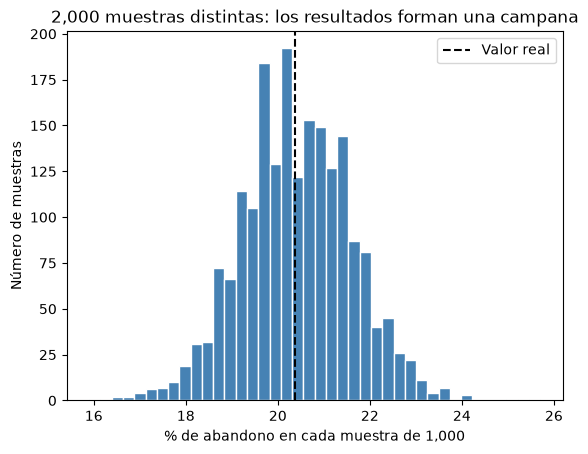

In [9]:
# QUÉ HACE ESTA CELDA: Dibuja los 2,000 resultados: forman una campana
# hist dibuja un histograma: barras que cuentan cuántos valores caen en cada rango; bins = número de barras
plt.hist(resultados * 100, bins=40, color="steelblue", edgecolor="white")
# el promedio de una columna de 0 y 1 (o True y False) es la proporción; × 100 da el porcentaje
plt.axvline(abandono.mean() * 100, color="black", linestyle="--", label="Valor real")
# textos de los ejes y título de la gráfica
plt.xlabel("% de abandono en cada muestra de 1,000")
plt.ylabel("Número de muestras")
plt.title("2,000 muestras distintas: los resultados forman una campana")
# muestra el cuadro que explica cada línea o color
plt.legend()
# muestra la gráfica en pantalla
plt.show()

## 2.4 Error estándar: cuánto "brinca" el resultado

🧠 **En palabras simples:** el **error estándar** mide **qué tan ancha es esa campana**, es decir, cuánto cambia el resultado de una muestra a otra. No es una "equivocación": es el **tamaño típico del brinco** por azar.

Lo interesante es que **no hace falta sacar 2,000 muestras** para conocerlo: existe una fórmula que lo calcula con **una sola muestra**. Comprobémoslo:

In [10]:
# QUÉ HACE ESTA CELDA: Compara el error estándar medido con las 2,000 muestras contra el de la fórmula
# proporción real de abandono en los 10,000 clientes
p = abandono.mean()
# tamaño de muestra elegido: 1,000 (redondeo hacia arriba del mínimo)
n = 1000
# np.std mide cuánto varían los 2,000 resultados: es el brinco medido
brinco_simulado = np.std(resultados)
# fórmula del error estándar de una proporción: raíz de p(1 − p) / n
brinco_formula = np.sqrt(p * (1 - p) / n)
print("Brinco medido con 2,000 muestras:", brinco_simulado)
print("Brinco calculado con la fórmula:", brinco_formula)

Brinco medido con 2,000 muestras: 0.011973350397862745
Brinco calculado con la fórmula: 0.012736024104876686


La pequeña diferencia entre los dos números no es un error: se debe a que cada muestra es el 10 % de todos los clientes, algo que se corrige en el nivel 3.6.

🎓 **Nivel experto:** el error estándar de una proporción es $EE = \sqrt{\dfrac{p(1-p)}{n}}$ y el de un promedio es $EE = \dfrac{s}{\sqrt n}$. En ambas fórmulas $n$ está **dividiendo**: **más clientes en la muestra → brincos más pequeños → resultados más precisos**.

## 2.5 El Teorema del Límite Central: por qué la campana aparece casi siempre

🧠 **En palabras simples:** aunque los datos de cada cliente **no** tengan forma de campana, el **promedio de una muestra grande sí la tiene**. Esto es una especie de "ley mágica" de la estadística y es la razón por la que las fórmulas funcionan en muchísimos casos.

💻 **Lo vemos con los datos:** el saldo de los clientes **no** es una campana (hay muchísimos en cero). Pero el *promedio* del saldo de muchas muestras sí lo es:

In [11]:
# QUÉ HACE ESTA CELDA: Simula 2,000 muestras de 200 clientes y calcula el saldo promedio de cada una
# toma sólo la columna del saldo
saldo = clientes["Balance"]

# 2,000 muestras de 200 clientes, sin reemplazo
# np.tile repite la lista de clientes, una copia por fila
copias_saldo = np.tile(saldo.to_numpy(), (2000, 1))
# permuted revuelve al azar el orden de los clientes dentro de cada fila
barajadas_saldo = generador.permuted(copias_saldo, axis=1)
# toma las primeras columnas de cada fila: una muestra sin clientes repetidos
muestras_saldo = barajadas_saldo[:, :200]
# mean(axis=1) saca el promedio de cada fila: un resultado por muestra
promedios = muestras_saldo.mean(axis=1)
print("Promedios calculados:", len(promedios))

Promedios calculados: 2000


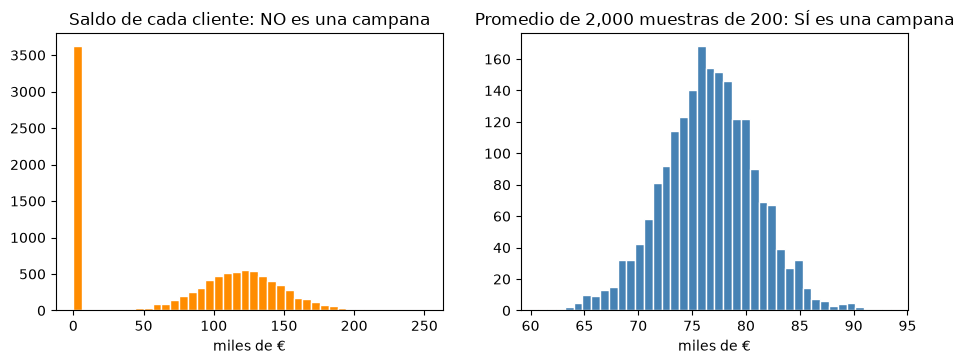

In [12]:
# QUÉ HACE ESTA CELDA: Dibuja dos gráficas: los saldos de cada cliente y los promedios de las muestras
# crea el lienzo de la gráfica; figsize = (ancho, alto)
plt.figure(figsize=(11, 3.6))

# subplot(1, 2, 1): cuadrícula de 1 fila y 2 columnas; se dibuja en la 1.ª
plt.subplot(1, 2, 1)
# hist dibuja un histograma: barras que cuentan cuántos valores caen en cada rango; bins = número de barras
plt.hist(saldo / 1000, bins=40, color="darkorange", edgecolor="white")
# textos de los ejes y título de la gráfica
plt.title("Saldo de cada cliente: NO es una campana")
plt.xlabel("miles de €")

# ahora se dibuja en la 2.ª posición (la de la derecha)
plt.subplot(1, 2, 2)
plt.hist(promedios / 1000, bins=40, color="steelblue", edgecolor="white")
plt.title("Promedio de 2,000 muestras de 200: SÍ es una campana")
plt.xlabel("miles de €")

# muestra la gráfica en pantalla
plt.show()

🎓 **Nivel experto:** el **Teorema del Límite Central (TLC)** dice que, con muestras suficientemente grandes (regla práctica: 30 o más), la distribución del promedio muestral se aproxima a una normal, sin importar la forma de los datos originales.

---
# 🟠 Nivel 3 · Intervalos de confianza

## 3.1 De un número a un rango

🧠 **En palabras simples:** decir "el 20.6 % de los clientes se va" suena exacto, pero sabemos que con otra muestra saldría otro número. Es más honesto decir: **"entre 18 % y 23 % de los clientes se va"**. Ese rango se llama **intervalo de confianza**.

🍲 **Ejemplo cotidiano:** el pronóstico del clima no dice "mañana habrá 24.3 °C"; dice "entre 22 y 26 °C". Es menos preciso, pero mucho más confiable.

## 3.2 ¿Cómo se construye el rango?

🧠 **En palabras simples:** tomas tu resultado y le sumas y restas **"unos dos brincos"** (dos errores estándar). Eso que sumas y restas se llama **margen de error**.

$$\text{rango} = \text{resultado de la muestra} \;\pm\; \underbrace{\text{(unos 2)} \times \text{(tamaño del brinco)}}_{\text{margen de error}}$$

¿Por qué "unos 2"? Porque en una campana, **el 95 % de los resultados cae a menos de 1.96 brincos del centro**. Comprobémoslo con las 2,000 muestras de antes:

In [13]:
# QUÉ HACE ESTA CELDA: Cuenta qué % de las 2,000 muestras quedó a menos de 1.96 errores estándar del valor real
# np.abs quita el signo: distancia de cada muestra al valor real
distancia = np.abs(resultados - p)
# True si la muestra quedó a menos de 1.96 brincos del valor real
cerca = distancia <= 1.96 * brinco_formula
# el promedio de una columna de 0 y 1 (o True y False) es la proporción; × 100 da el porcentaje
print("% de muestras a menos de 1.96 brincos del valor real:", cerca.mean() * 100)

% de muestras a menos de 1.96 brincos del valor real: 96.35000000000001


Sale un poco más de 95 % por la misma razón de antes (cada muestra es el 10 % del total; nivel 3.6). La idea se confirma: **con ±1.96 brincos se atrapa el valor real alrededor del 95 % de las veces**.

🎓 **Nivel experto:** el número 1.96 se llama **valor crítico** y se escribe $z$. La fórmula del intervalo para una proporción es $IC = \hat p \pm z \sqrt{\dfrac{\hat p (1-\hat p)}{n}}$.

## 3.3 ¿Qué significa "95 % de confianza"?

🧠 **En palabras simples:** significa que **el método acierta 95 de cada 100 veces**. Si 100 equipos distintos sacaran cada uno su muestra y calcularan su rango, unos 95 rangos contendrían el valor real y unos 5 no.

🍲 **Ejemplo cotidiano:** es como un pescador que lanza una **red**. Sabe que su red atrapa al pez 95 de cada 100 lanzamientos. Cuando lanza una vez, no sabe con certeza si esta vez lo atrapó, pero **confía en su red**. El pez (el valor real) no se mueve; lo que cambia en cada lanzamiento es dónde cae la red.

⚠️ Por eso **no** se dice "hay 95 % de probabilidad de que el valor real esté aquí", sino "construí este rango con un método que acierta el 95 % de las veces".

## 3.4 ¿Más confianza o más precisión?

🧠 **En palabras simples:** si quieres estar **más seguro** (99 % en lugar de 95 %), necesitas una **red más grande** → el rango sale **más ancho** (menos preciso). Si aceptas menos seguridad (90 %), la red es más chica → rango más estrecho. **No se pueden tener las dos cosas con los mismos datos.**

| Confianza | "Cuántos brincos" ($z$) | Rango |
|---|---|---|
| 90 % | 1.645 | Más estrecho |
| 95 % | 1.96 | Equilibrado |
| 99 % | 2.576 | Más ancho |

## 3.5 ¿Cuántos clientes hay que revisar? (tamaño de muestra)

🧠 **En palabras simples:** antes de empezar se decide **qué margen de error se acepta** (por ejemplo, ±3 puntos) y, con eso, se calcula cuántos clientes revisar. Más precisión = más clientes. Y ojo: **para reducir el margen a la mitad hay que revisar 4 veces más clientes**, porque el tamaño de la muestra está dentro de una raíz cuadrada.

🎓 **Nivel experto:** $n = \dfrac{z^2\, p(1-p)}{E^2}$, donde $E$ es el margen de error deseado. Si no se conoce $p$, se usa 0.5 porque es el valor que da la muestra más grande (el caso "más prudente").

## 3.6 Cuando la población es pequeña

🧠 **En palabras simples:** si revisas una parte grande del total, ya sabes bastante de él y la incertidumbre es menor. Por eso, cuando la muestra es más del 5 % de la población, el margen de error se **achica un poco** con un factor de corrección.

🍲 **Ejemplo cotidiano:** si pruebas una cucharada de una olla gigante, sabes poco; si pruebas una cucharada de un tazón pequeño, ya probaste buena parte del tazón.

🎓 **Nivel experto:** **factor de corrección por población finita**: $\sqrt{\dfrac{N-n}{N-1}}$, donde $N$ es el tamaño de la población. Con $N$ = 10,000 y $n$ = 1,000 vale 0.949 (el margen se reduce ≈ 5 %).

## 3.7 Cuando no conocemos la dispersión real: la distribución t

🧠 **En palabras simples:** para el promedio necesitamos saber qué tan dispersos están los datos **en toda la población**, pero sólo lo conocemos en la muestra. Para compensar esa duda extra se usa una campana **un poquito más ancha**, llamada **t de Student**. Con muestras grandes, casi no se distingue de la normal.

---
# 🔴 Nivel 4 · Herramientas de experto

## 4.1 Comparar dos grupos: ¿el rango toca el cero?

🧠 **En palabras simples:** para saber si los clientes inactivos se van **más** que los activos, se calcula un rango para **la diferencia** entre ambos grupos.
- Si el rango **incluye el 0** (por ejemplo, de −2 a +5), podría no haber diferencia real.
- Si el rango **no incluye el 0** (por ejemplo, de +6 a +16), hay evidencia de una diferencia real en la población.

🎓 **Nivel experto:** intervalos para **diferencia de proporciones** ($p_1 - p_2$) y **diferencia de medias** ($\mu_1 - \mu_2$). Para medias se usa el **método de Welch**, que no supone que los dos grupos tengan la misma dispersión.

## 4.2 Asociación no es causa

🧠 **En palabras simples:** que dos cosas ocurran juntas **no significa que una provoque la otra**.

🍲 **Ejemplo cotidiano:** cuando se venden más helados, hay más personas ahogadas en el mar. ¿Los helados ahogan gente? No: ambas cosas suben **en verano**. En el banco, que los inactivos se vayan más no prueba que la inactividad *provoque* la salida; quizá el cliente dejó de usar la cuenta *porque* ya planeaba irse.

## 4.3 ¿La muestra se parece a la población? La prueba ji cuadrada y el p-valor

🧠 **En palabras simples:** para revisar que la muestra quedó "bien revuelta", se compara, por ejemplo, el porcentaje de clientes de cada país en la muestra y en la población. La **prueba ji cuadrada** (se escribe χ²) responde: *¿estas diferencias son normales para una muestra al azar o son sospechosamente grandes?* Su resultado es el **p-valor**:
- **p-valor grande** (mayor a 0.05) → las diferencias son normales; todo bien.
- **p-valor pequeño** (menor a 0.05) → las diferencias son raras; algo podría estar mal.

🍲 **Ejemplo cotidiano:** si lanzas una moneda 10 veces y salen 6 águilas, no es raro (p-valor grande). Si salen 10 de 10, sospechas que la moneda está cargada (p-valor pequeño).

## 4.4 Remuestreo (bootstrap): comprobar sin fórmulas

🧠 **En palabras simples:** para comprobar que una fórmula funciona, se puede "jugar" con la propia muestra: se sacan miles de **nuevas muestras de la muestra** (como sacar papelitos de una urna y regresarlos) y se observa cuánto varía el resultado. Si coincide con lo que dice la fórmula, la fórmula es confiable.

## 4.5 Tomar una decisión con incertidumbre

🧠 **En palabras simples:** los números no deciden solos; hay que traducirlos a **dinero y consecuencias**. Las herramientas que se usan en el cuaderno 03:
- **Umbral de rentabilidad:** el porcentaje de abandono a partir del cual una campaña de retención **gana más de lo que cuesta**.
- **Escenarios:** se evalúa la decisión con el **extremo bajo** del rango (escenario pesimista), con el valor central y con el **extremo alto** (optimista).
- **Mejor peor caso** (en inglés *maximin*): elegir la opción que, **aun si todo sale mal**, deja el mejor resultado.
- **Arrepentimiento:** cuánto dinero dejarías de ganar por no haber elegido la mejor opción; se busca la opción con la que menos te arrepentirías.
- **Sensibilidad:** cambiar un supuesto (por ejemplo, qué tan efectiva es la campaña) para ver si la decisión cambia.

---
# 📖 Glosario rápido

| Término | En palabras simples | Nivel |
|---|---|---|
| Variable | Una columna: algo que cambia de un cliente a otro | 🟢 1 |
| Población | Todo el grupo que nos interesa (10,000 clientes) | 🟢 1 |
| Muestra | El pedazo que revisamos (1,000 clientes) | 🟢 1 |
| Parámetro | Número real de toda la población (normalmente desconocido) | 🟢 1 |
| Estadístico | El mismo número calculado con la muestra | 🟢 1 |
| Proporción ($p$, $\hat p$) | Porcentaje de "sí" | 🟢 1 |
| Media o promedio ($\mu$, $\bar x$) | Suma ÷ cuántos son | 🟢 1 |
| Mediana | El valor de en medio | 🟢 1 |
| Desviación estándar ($s$) | Qué tan regados están los datos | 🟢 1 |
| Muestreo aleatorio | Sortear a quién revisar | 🟡 2 |
| Sesgo | Error por elegir mal (no "revolver la sopa") | 🟡 2 |
| Distribución normal | La forma de campana | 🟡 2 |
| Error estándar | Cuánto "brinca" el resultado de una muestra a otra | 🟡 2 |
| Teorema del Límite Central | Los promedios forman campana aunque los datos no | 🟡 2 |
| Intervalo de confianza | Rango "entre tanto y tanto" | 🟠 3 |
| Margen de error | Lo que se suma y resta al resultado | 🟠 3 |
| Nivel de confianza (95 %) | Qué tan seguido acierta el método | 🟠 3 |
| Valor crítico ($z$ = 1.96) | "Cuántos brincos" sumar y restar | 🟠 3 |
| Distribución t | Campana un poco más ancha, para cuando hay más duda | 🟠 3 |
| Corrección por población finita | Achicar el margen cuando se revisa mucho del total | 🟠 3 |
| Diferencia de proporciones / medias | Comparar dos grupos | 🔴 4 |
| Método de Welch | Forma segura de comparar promedios de dos grupos | 🔴 4 |
| Prueba ji cuadrada (χ²) y p-valor | Revisar si unas diferencias son normales o sospechosas | 🔴 4 |
| Bootstrap (remuestreo) | Comprobar resultados sacando muestras de la muestra | 🔴 4 |
| Asociación vs. causa | Ocurrir juntos ≠ provocarse | 🔴 4 |
| Mejor peor caso (*maximin*) | Elegir lo que deja mejor resultado si todo sale mal | 🔴 4 |

➡️ **Ahora sí, a aplicar todo:** `01_conocer_y_preparar_datos.ipynb`.